The absorption module is used to calculate TBabs-like photoelectric absorption and $\gamma-\gamma$ absorption on the background field of the star photons. Both photoelectric absobtion and gg-absorption coefficients should not be taken too seriously: if your task is to investigate the importance of absorption on something or the dependence of absorption coefficients themselves on parameters, I would use `ibsen.absorption` only as the first estimate. Even though both $\tau$ should not differ from the properly calculated ones more than a few percent, I mostly optimized them both to work fast, rathen than give precise results.

First, let's look at the TBabs absorption. I borrowed the dependence $\sigma(E)$ from https://arxiv.org/pdf/astro-ph/0008425, which is tabulated and shipped together with `ibsen`, and the absorption coefficient is calculated as
\begin{equation}
\mathrm{abs}_\mathrm{ph}(E) = e^{-\sigma (E) N_\mathrm{H}}.
\end{equation}


Text(0, 0.5, '$e^{-\\tau}$')

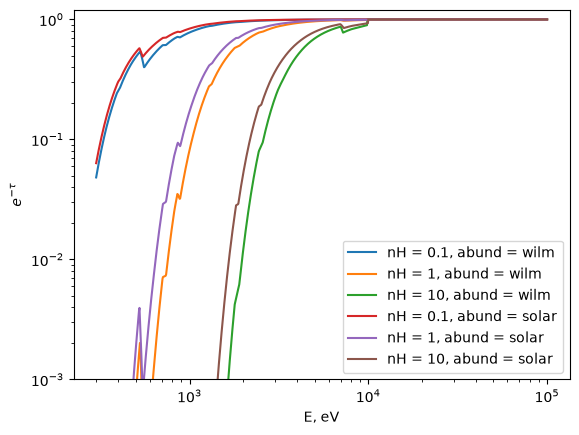

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import ibsen.absorption.absorption as absb

E = np.geomspace(3e2, 1e5, 1000)
for abund in ('wilm', 'solar'):
    for Nh in (0.1, 1, 10):
        photoel_coef = absb.abs_photoel(E=E, # in eV
                                       Nh = Nh, # in 1e22 [g cm^-2], as in XSpec
                                        abund=abund,
                                       )
        plt.plot(E, photoel_coef, label=f"nH = {Nh}, abund = {abund}")
plt.legend()
plt.xscale('log')
plt.yscale('log')
plt.ylim(1e-3, 1.2)
plt.xlabel(r'E, eV')
plt.ylabel(r'$e^{-\tau}$')




For the $\gamma-\gamma$ absorption there is a function written by me that calculates $\tau_{\gamma \gamma}(E, x, y, z ,T_\mathrm{s}, R_\mathrm{s}, ...)$, where $(x, y)$ are coordinates in the orbital plane. It follows Dubus 2006 (https://arxiv.org/pdf/astro-ph/0509633), and Sushch & van Soelen 2017, 2023 (https://arxiv.org/pdf/1703.00680, https://arxiv.org/pdf/2310.01102) in a "point-source approximation". Essentially, it is the assumption that the integrand (see further) is a constant for any direction crossing the star, and zero otherwise. With this assumption,

\begin{equation}
\tau_{\gamma \gamma}(e) = \pi \int_0^\infty dl (1-\mu_\mathrm{int}(l)) \left(\frac{R_\mathrm{opt}}{d(l)}\right)^2 
\int_{e_\mathrm{min}}^\infty de_* \sigma_{\gamma \gamma}(e, e_*, l) n_*(e_*, l),
\end{equation}

where $l$ is a distance traveled by a VHE photon of energy $e$ from the emission point, and  see Dubus (2006), Sushch, van Soelen (2023) for the rest.

While you _can_ use this function: `ibsen.absorption.absorption.tau_gg_iso_2d`, it was not vectorized or parallzied, and also even one calculation at one energy takes a considerable time. That is why in a real calculation it's best to pre-compute the opacities, save them in a binary format, and later to interpolate.

The function `tabulate_absgg_d_mu` performs the tabulation. If the system is ``fixed'', e.g. if we know $T_s$ and $R_s$, the function above actually depends only on three parameters: $E, d_{\rm init}, \mu_{\rm init}$. So it makes sense to tabulate onto E_grid x d_grid x mu_grid.

For example, let's tabulate such table:

**the cell is commented because it takes about a minute, and it creates a file, so if you are sure you want to run it, just uncomment it**

In [2]:
from ibsen.orbit import Orbit
from ibsen.absorption.absorption import tabulate_absgg, tabulate_absgg_d_mu
import time
DAY = 86400

start = time.time()
tabulate_absgg_d_mu(nr=18, nmu=18, ne=38, # number of nods over r, phi, E. 
                                          # For PSRB, this was tested to already give results with ~3%
               T_s=3e4, R_s=10*7e10,
               to_return=False, # whether to return res, xx, yy, es (see docs)
               fast=True, # Whether to calculate 10 times faster but ~30% incorrectly.
               filename='gg_abs_test_d_mu', # filename to save the result to. You'll have to pass it as an argument to the interpolator
              )
print(f'took {time.time() - start} s')


took 140.67954087257385 s


The fastest way to get the $\gamma-\gamma$ absorption coefficient, especially if it has to be evaluated for an array of photon energies, is to read this table and interpolate the result for the desirable spatial coordinates and energies. For this purpose, there is a function which is used in all spectrum-related calculations. Let's compare performance of this interpolator function VS "honest" calculation:

In [4]:
orb = Orbit(T=1000*DAY, e=0.4, 
            M_s=30*2e33, M_p=1.4*2e33,
            nu_los=np.deg2rad(90.), 
            incl_los=np.deg2rad(30.))

Interpolation,  0.019173383712768555
Calculation,  1.4244952201843262
Interpolation,  0.0005860328674316406
Calculation,  1.45707368850708
Interpolation,  0.00047969818115234375
Calculation,  1.463667392730713
Interpolation,  0.0005538463592529297
Calculation,  1.447650671005249
Interpolation,  0.0005445480346679688
Calculation,  1.4535443782806396


/tmp/ipykernel_10766/108998531.py:26: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


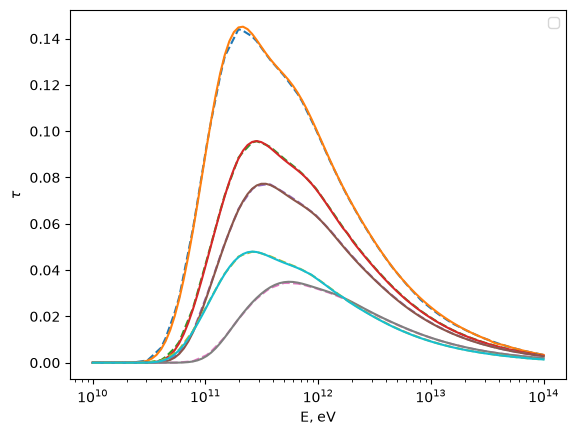

In [6]:
"""
Test over energies
"""
from ibsen.absorption.absorption import gg_tab, gg_tab_d_mu

plt.close('all')
eplot = np.geomspace(1e10, 1e14, 100)

for tplot in (-50, -10, 5, 60, 600):
    tplot = tplot * DAY
    x, y = orb.x(tplot), orb.y(tplot)
    st = time.time()
    res_= gg_tab_d_mu(eplot, vec_init=np.array([x, y, 0.]),
                      n_los=orb.unit_los,
                      what_return='tau', filename='gg_abs_test_d_mu')
    print('Interpolation, ', time.time() - st)
    plt.plot(eplot, res_, ls='--')
    from ibsen.absorption.absorption import tau_gg_iso_2d
    st = time.time()

    res_an = np.array([tau_gg_iso_2d(eg=e_/5.11e5, x=x, y=y, R_s=10*7e10, T_s=3e4,
                nu_los=orb.nu_los, incl_los=orb.incl_los, fast=True)
                      for e_ in eplot])
    plt.plot(eplot, res_an)
    print('Calculation, ', time.time() - st)
plt.legend()

plt.xlabel('E, eV')
plt.ylabel(r'$\tau$')


plt.xscale('log')
plt.show()

Interpolation,  0.0015611648559570312
Calculation,  1.0862298011779785
Interpolation,  0.0004432201385498047
Calculation,  1.2532916069030762
Interpolation,  0.0004267692565917969
Calculation,  1.90151047706604


/tmp/ipykernel_10766/3731488004.py:29: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


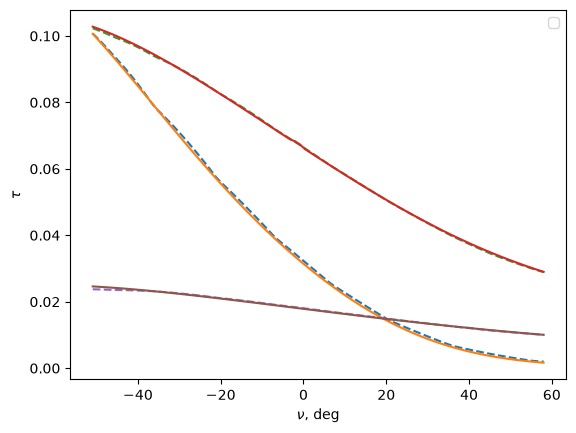

In [10]:
"""
Test over coordinates: compare tau(1 TeV) over the pulsar orbit tab VS analyt
"""
plt.close('all')  

tplot = np.linspace(-60, 70, 100) * DAY
x, y, nu = orb.x(tplot), orb.y(tplot), orb.true_an(tplot)
vec = np.zeros((x.size, 3))
vec[:, 0]=x
vec[:, 1]=y
for E in (1e11, 1e12,  1e13, ):
    st = time.time()
    res_ = gg_tab_d_mu(E, vec_init=vec,
                       n_los=orb.unit_los,
                       what_return='tau', 
                       filename='gg_abs_test_d_mu',
                      )
    print('Interpolation, ', time.time() - st)
    plt.plot(nu/np.pi*180, res_, ls='--')    
    st = time.time()

    res_an = np.array([
        tau_gg_iso_2d(eg=E/5.11e5, x=xi, y=yi, R_s=10*7e10, T_s=3e4,
                nu_los=orb.nu_los, incl_los=orb.incl_los, fast=True) 
                       for xi, yi in zip(x, y) ])
    plt.plot(nu/np.pi*180, res_an)
    print('Calculation, ', time.time() - st)
        
plt.legend()

plt.xlabel(r'$\nu$, deg')
plt.ylabel(r'$\tau$')


plt.show()

Another method to tabulate the absorption is to use the script `tab_gg_opac` in `IBSEn` directly from the command line. You can run it from the command line like this (from the IBSEn folder):

```bash
> cd IBSEn
> python3 tab_gg_opac.py --T 1000.0 --e 0.4 --M 30.0 --nu_los 90.0 --incl_los 30.0 --Topt 3e4 --Ropt 10 --filename 'gg_test' --nrho 15 --nphi 16 --ne 24 --fast True
```

Note the filename convention: if you want to tabulate it for a centain binary which is recognized by IBSEn as `<name>`, you have to name the file `gg_abs_<name>_d_mu`. For example, IBSEn recognizes the binary LS I+61 as 'ls61'. For this binary, you have to name the file `gg_abs_ls61_d_mu`. Since 'test' is one of the recognized inputs (it corresponds to the test bianry system of Sushch, van Soelen 2023), you can just enter `filename='test'` in the cells above.